In [33]:
!pip install shap

In [34]:
import pandas as pd
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error
from sklearn.preprocessing import LabelEncoder
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
import math
import shap

In [35]:
data = pd.read_csv('./train_feature_v5.csv')
test_df = pd.read_csv('./test_feature_v5.csv')

In [36]:
data1 = data.copy()
test_df1 = test_df.copy()

# Without additional PCA, only using Label Encoder for binary values

In [37]:
pca_cols_train = data.iloc[:,5:27]

le = LabelEncoder()
pca_cols_train = pca_cols_train.apply(le.fit_transform)

data = data.drop(columns=pca_cols_train.columns)
data = pd.concat([data, pca_cols_train], axis=1)

pca_cols_test = test_df.iloc[:,5:27]

le = LabelEncoder()
pca_cols_test = pca_cols_test.apply(le.fit_transform)

test_df = test_df.drop(columns=pca_cols_train.columns)
test_df = pd.concat([test_df, pca_cols_test], axis=1)

In [38]:
pca_cols_train = data.iloc[:,7:13]

le = LabelEncoder()
pca_cols_train = pca_cols_train.apply(le.fit_transform)

data = data.drop(columns=pca_cols_train.columns)
data = pd.concat([data, pca_cols_train], axis=1)

pca_cols_test = test_df.iloc[:,7:13]

le = LabelEncoder()
pca_cols_test = pca_cols_test.apply(le.fit_transform)

test_df = test_df.drop(columns=pca_cols_train.columns)
test_df = pd.concat([test_df, pca_cols_test], axis=1)

# With additional PCA

In [39]:
pca_cols_train = data1.iloc[:,5:27]

le = LabelEncoder()
pca_cols_train = pca_cols_train.apply(le.fit_transform)

pca = PCA(n_components=5)  # Specify the number of components
pca_result = pca.fit_transform(pca_cols_train)
pca_result = pd.DataFrame(pca_result, columns=[f'pca_{i}' for i in range(5)])

data1 = data1.drop(columns=pca_cols_train.columns)
data1 = pd.concat([data1, pca_result], axis=1)

pca_cols_test = test_df1.iloc[:,5:27]

le = LabelEncoder()
pca_cols_test = pca_cols_test.apply(le.fit_transform)

pca = PCA(n_components=5)  # Specify the number of components
pca_result = pca.fit_transform(pca_cols_test)
pca_result = pd.DataFrame(pca_result, columns=[f'pca_{i}' for i in range(5)])

test_df1 = test_df1.drop(columns=pca_cols_train.columns)
test_df1 = pd.concat([test_df1, pca_result], axis=1)

In [40]:
pca_cols_train = data1.iloc[:,7:13]

le = LabelEncoder()
pca_cols_train = pca_cols_train.apply(le.fit_transform)

pca = PCA(n_components=3)  # Specify the number of components
pca_result = pca.fit_transform(pca_cols_train)
pca_result = pd.DataFrame(pca_result, columns=[f'pca_{i}_double' for i in range(3)])

data1 = data1.drop(columns=pca_cols_train.columns)
data1 = pd.concat([data1, pca_result], axis=1)

pca_cols_test = test_df1.iloc[:,7:13]

le = LabelEncoder()
pca_cols_test = pca_cols_test.apply(le.fit_transform)

pca = PCA(n_components=3)  # Specify the number of components
pca_result = pca.fit_transform(pca_cols_test)
pca_result = pd.DataFrame(pca_result, columns=[f'pca_{i}_double' for i in range(3)])

test_df1 = test_df1.drop(columns=pca_cols_train.columns)
test_df1 = pd.concat([test_df1, pca_result], axis=1)

In [41]:
X = data.drop(columns=["price"]).values  # Exclude target variable for input
y = data["price"].values  # Target variable

In [42]:
print("Min value in dataset:", X.min())
print("Max value in dataset:", X.max())

Min value in dataset: -381777.5428713535
Max value in dataset: 39780000.0


In [43]:
# Normalize features and target variable
scaler_X = StandardScaler()
X_normalized = scaler_X.fit_transform(X)
scaler_y = StandardScaler()
y_normalized = scaler_y.fit_transform(y.reshape(-1, 1)).flatten()

In [44]:
# Split into training and validation sets
X_train, X_val, y_train, y_val = train_test_split(X_normalized, y_normalized, test_size=0.2, random_state=42)

# Convert to PyTorch tensors
X_train_tensor = torch.tensor(X_train, dtype=torch.float32)
y_train_tensor = torch.tensor(y_train, dtype=torch.float32).view(-1, 1)
X_val_tensor = torch.tensor(X_val, dtype=torch.float32)
y_val_tensor = torch.tensor(y_val, dtype=torch.float32).view(-1, 1)

# Create DataLoaders for training and validation
train_dataset = TensorDataset(X_train_tensor, y_train_tensor)
val_dataset = TensorDataset(X_val_tensor, y_val_tensor)
train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=32, shuffle=False)

In [45]:
# Training function with early stopping
def train_model(model, train_loader, val_loader, criterion, optimizer, epochs=20):
    best_val_loss, epochs_no_improve = float('inf'), 0
    training_loss = []
    validation_loss = []

    for epoch in range(epochs):
        model.train()
        train_loss = 0.0
        for inputs, targets in train_loader:
            optimizer.zero_grad()
            outputs = model(inputs)
            loss = criterion(outputs, targets)
            loss.backward()
            optimizer.step()
            train_loss += loss.item() * inputs.size(0)

        # Validation phase
        model.eval()
        val_loss = 0.0
        with torch.no_grad():
            for inputs, targets in val_loader:
                outputs = model(inputs)
                loss = criterion(outputs, targets)
                val_loss += loss.item() * inputs.size(0)

        # Calculate average training loss for the epoch
        train_loss /= len(train_loader.dataset)
        training_loss.append(train_loss)
        val_loss /= len(val_loader.dataset)
        validation_loss.append(val_loss)

        print(f"Epoch {epoch+1}/{epochs}, Train Loss: {train_loss:.4f}, Val Loss: {val_loss:.4f}")

        # Early stopping check
        if val_loss < best_val_loss:
            best_val_loss = val_loss
            epochs_no_improve = 0
            best_model = model.state_dict()  # Save the best model's parameters
        else:
            epochs_no_improve += 1
            if epochs_no_improve >= patience:
                print(f"Early stopping triggered after {epoch+1} epochs.")
                model.load_state_dict(best_model)  # Load the best model parameters
                break

    return training_loss, validation_loss

# Baseline Neural Network Model

In [46]:
# Define the neural network model
class PricePredictionNN(nn.Module):
    def __init__(self, input_dim):
        super(PricePredictionNN, self).__init__()
        self.model = nn.Sequential(
            nn.Linear(input_dim, 128),
            nn.ReLU(),
            nn.Linear(128, 64),
            nn.ReLU(),
            nn.Linear(64, 32),
            nn.ReLU(),
            nn.Linear(32, 1)  # Single output neuron for regression
        )

    def forward(self, x):
        return self.model(x)

In [47]:
# Initialize the model, loss function, and optimizer
input_dim = X_train.shape[1]
patience = 10  # Number of epochs to wait for improvement

model = PricePredictionNN(input_dim)
criterion = nn.MSELoss()
optimizer = optim.Adam(model.parameters(), lr=1e-3, weight_decay=1e-5)

training_loss, validation_loss = train_model(model, train_loader, val_loader, criterion, optimizer, epochs=100)

Epoch 1/100, Train Loss: 0.0714, Val Loss: 0.0296
Epoch 2/100, Train Loss: 0.0328, Val Loss: 0.0265
Epoch 3/100, Train Loss: 0.0272, Val Loss: 0.0259
Epoch 4/100, Train Loss: 0.0299, Val Loss: 0.0284
Epoch 5/100, Train Loss: 0.0271, Val Loss: 0.0229
Epoch 6/100, Train Loss: 0.0229, Val Loss: 0.0229
Epoch 7/100, Train Loss: 0.0205, Val Loss: 0.0202
Epoch 8/100, Train Loss: 0.0162, Val Loss: 0.0194
Epoch 9/100, Train Loss: 0.0155, Val Loss: 0.0199
Epoch 10/100, Train Loss: 0.0304, Val Loss: 0.0223
Epoch 11/100, Train Loss: 0.0177, Val Loss: 0.0192
Epoch 12/100, Train Loss: 0.0131, Val Loss: 0.0198
Epoch 13/100, Train Loss: 0.0160, Val Loss: 0.0383
Epoch 14/100, Train Loss: 0.0115, Val Loss: 0.0175
Epoch 15/100, Train Loss: 0.0083, Val Loss: 0.0525
Epoch 16/100, Train Loss: 0.0162, Val Loss: 0.0206
Epoch 17/100, Train Loss: 0.0127, Val Loss: 0.0182
Epoch 18/100, Train Loss: 0.0130, Val Loss: 0.0182
Epoch 19/100, Train Loss: 0.0121, Val Loss: 0.0164
Epoch 20/100, Train Loss: 0.0084, Val Lo

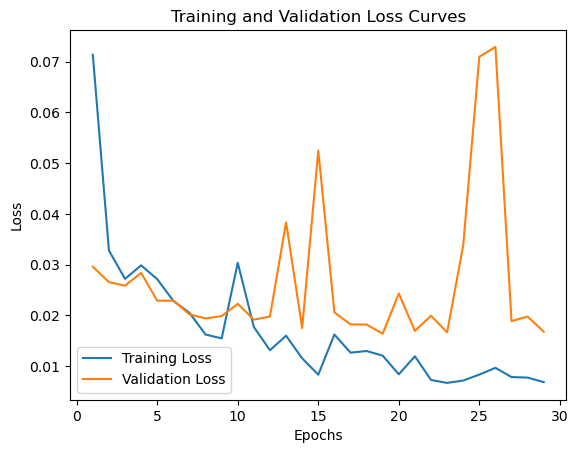

In [48]:
# Plot the loss curves
epochs = range(1, len(training_loss) + 1)
plt.plot(epochs, training_loss, label='Training Loss')
plt.plot(epochs, validation_loss, label='Validation Loss')

plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.title('Training and Validation Loss Curves')
plt.legend()
plt.show()

In [49]:
model.eval()

# Make predictions on the validation set
with torch.no_grad():
    val_predictions = model(X_val_tensor).numpy().flatten()
    val_targets = y_val_tensor.numpy().flatten()

# Calculate RMSE on the validation set (converting back from normalized to original scale)
val_predictions_original_scale = scaler_y.inverse_transform(val_predictions.reshape(-1, 1)).flatten()
val_targets_original_scale = scaler_y.inverse_transform(val_targets.reshape(-1, 1)).flatten()

# Calculate RMSE
rmse = np.sqrt(mean_squared_error(val_targets_original_scale, val_predictions_original_scale))
print(f"Validation RMSE: {rmse:.4f}")

Validation RMSE: 20158.2148


In [50]:
# Set 1st model as best model based on RMSE first
best_model = model
best_rmse = rmse
all_loss = {
    'PricePredictionNN (Baseline)':
     {
        'train_loss':training_loss,
        'val_loss':validation_loss
     }
}

In [51]:
X_test_normalized = scaler_X.fit_transform(test_df.values)
X_test_tensor = torch.tensor(X_test_normalized, dtype=torch.float32)
test_dataset = TensorDataset(X_test_tensor)
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False)

predictions = []
model.eval()
with torch.no_grad():
    for inputs in test_loader:
        outputs = model(inputs[0])
        predictions.extend(outputs.numpy().flatten())

predictions = scaler_y.inverse_transform(np.array(predictions).reshape(-1, 1)).flatten()

test_results = pd.DataFrame({'Id': range(len(predictions)), 'Predicted': predictions})

test_results.to_csv('submission1.csv', index=False)

In [52]:
# KernelExplainer needs a function, so wrap the model to return predictions as numpy arrays
def model_predict(data):
    data = torch.from_numpy(data).float()  # Convert to tensor
    with torch.no_grad():
        return model(data).cpu().numpy()  # Get predictions as numpy

# Initialize KernelExplainer
explainer = shap.KernelExplainer(model_predict, X_test_normalized[:100])

# Calculate Shapley values (may take long)
shap_values = explainer.shap_values(X_test_normalized[:100])

  0%|          | 0/100 [00:00<?, ?it/s]

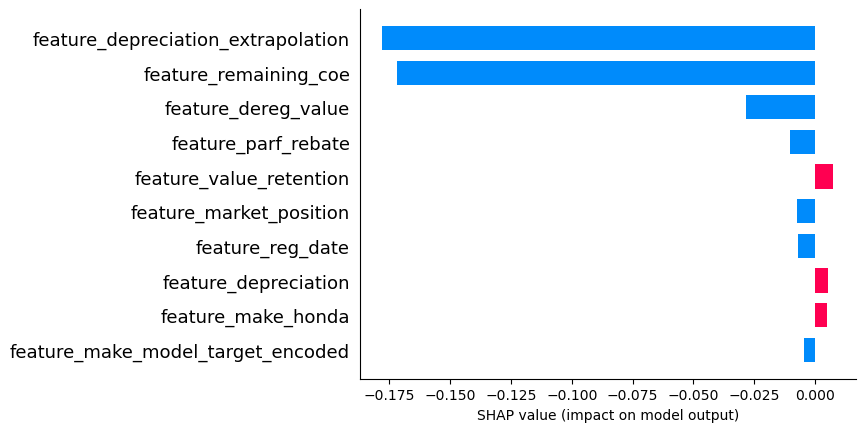

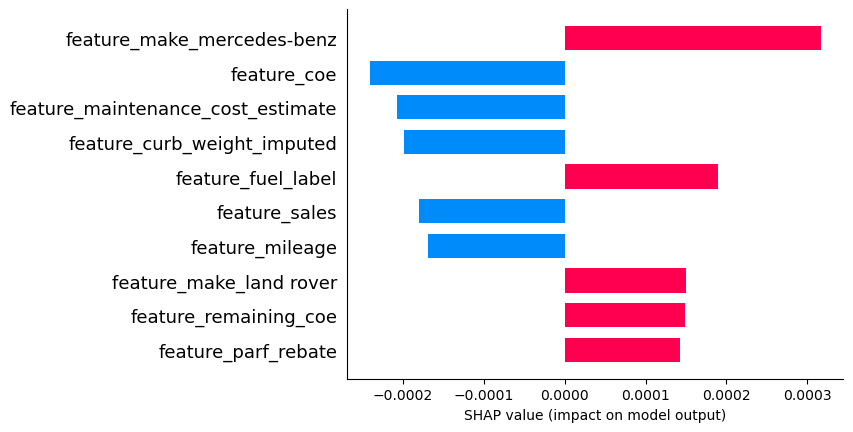

In [53]:
# Assuming you want to plot the SHAP values for the first sample and first output:
shap.bar_plot(shap_values[0,:,0], feature_names=test_df.columns, max_display=10)

# Or for the average SHAP values across all samples:
shap.bar_plot(np.mean(shap_values[:,:,0], axis=0), feature_names=test_df.columns, max_display=10)

# Training with a Larger model

In [54]:
# Larger model
class PricePredictionLarger(nn.Module):
    def __init__(self, input_dim):
        super(PricePredictionLarger, self).__init__()
        self.model = nn.Sequential(
            nn.Linear(input_dim, 256),
            nn.ReLU(),
            nn.Linear(256, 128),
            nn.ReLU(),
            nn.Linear(128, 64),
            nn.ReLU(),
            nn.Linear(64, 32),
            nn.ReLU(),
            nn.Linear(32, 1)  # Single output neuron for regression
        )

    def forward(self, x):
        return self.model(x)

In [55]:
# Initialize the model, loss function, and optimizer
input_dim = X_train.shape[1]
patience = 10  # Number of epochs to wait for improvement

model = PricePredictionLarger(input_dim)
criterion = nn.MSELoss()
optimizer = optim.Adam(model.parameters(), lr=1e-3, weight_decay=1e-5)

training_loss, validation_loss = train_model(model, train_loader, val_loader, criterion, optimizer, epochs=100)

Epoch 1/100, Train Loss: 0.0928, Val Loss: 0.0360
Epoch 2/100, Train Loss: 0.0376, Val Loss: 0.0270
Epoch 3/100, Train Loss: 0.0270, Val Loss: 0.0229
Epoch 4/100, Train Loss: 0.0284, Val Loss: 0.0221
Epoch 5/100, Train Loss: 0.0246, Val Loss: 0.0235
Epoch 6/100, Train Loss: 0.0307, Val Loss: 0.0225
Epoch 7/100, Train Loss: 0.0235, Val Loss: 0.0570
Epoch 8/100, Train Loss: 0.0280, Val Loss: 0.0247
Epoch 9/100, Train Loss: 0.0213, Val Loss: 0.0210
Epoch 10/100, Train Loss: 0.0139, Val Loss: 0.0272
Epoch 11/100, Train Loss: 0.0148, Val Loss: 0.0502
Epoch 12/100, Train Loss: 0.0196, Val Loss: 0.0194
Epoch 13/100, Train Loss: 0.0130, Val Loss: 0.0194
Epoch 14/100, Train Loss: 0.0112, Val Loss: 0.0557
Epoch 15/100, Train Loss: 0.0115, Val Loss: 0.0198
Epoch 16/100, Train Loss: 0.0155, Val Loss: 0.0372
Epoch 17/100, Train Loss: 0.0089, Val Loss: 0.0164
Epoch 18/100, Train Loss: 0.0105, Val Loss: 0.0170
Epoch 19/100, Train Loss: 0.0080, Val Loss: 0.0185
Epoch 20/100, Train Loss: 0.0079, Val Lo

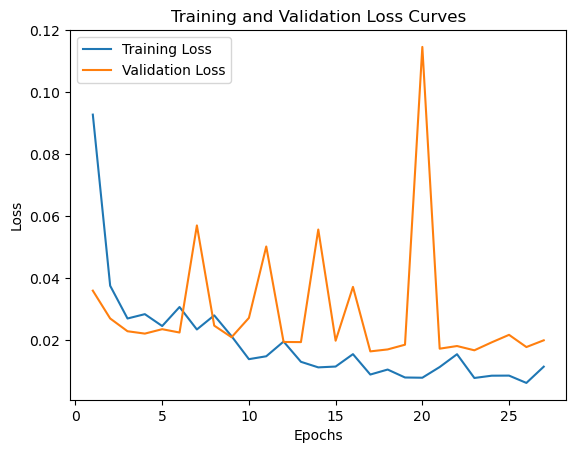

In [56]:
# Plot the loss curves
epochs = range(1, len(training_loss) + 1)
plt.plot(epochs, training_loss, label='Training Loss')
plt.plot(epochs, validation_loss, label='Validation Loss')

plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.title('Training and Validation Loss Curves')
plt.legend()
plt.show()

In [57]:
model.eval()

# Make predictions on the validation set
with torch.no_grad():
    val_predictions = model(X_val_tensor).numpy().flatten()
    val_targets = y_val_tensor.numpy().flatten()

# Calculate RMSE on the validation set (converting back from normalized to original scale)
val_predictions_original_scale = scaler_y.inverse_transform(val_predictions.reshape(-1, 1)).flatten()
val_targets_original_scale = scaler_y.inverse_transform(val_targets.reshape(-1, 1)).flatten()

# Calculate RMSE
rmse = np.sqrt(mean_squared_error(val_targets_original_scale, val_predictions_original_scale))
print(f"Validation RMSE: {rmse:.4f}")

Validation RMSE: 21979.7246


In [58]:
all_loss['PricePredictionLarger'] = {
    'train_loss':training_loss,
    'val_loss':validation_loss
}
if rmse < best_rmse:
    best_model = model
    best_rmse = rmse

In [59]:
X_test_normalized = scaler_X.fit_transform(test_df.values)
X_test_tensor = torch.tensor(X_test_normalized, dtype=torch.float32)
test_dataset = TensorDataset(X_test_tensor)
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False)

predictions = []
model.eval()
with torch.no_grad():
    for inputs in test_loader:
        outputs = model(inputs[0])
        predictions.extend(outputs.numpy().flatten())

predictions = scaler_y.inverse_transform(np.array(predictions).reshape(-1, 1)).flatten()

test_results = pd.DataFrame({'Id': range(len(predictions)), 'Predicted': predictions})

test_results.to_csv('submission2.csv', index=False)

In [60]:
# KernelExplainer needs a function, so wrap the model to return predictions as numpy arrays
def model_predict(data):
    data = torch.from_numpy(data).float()  # Convert to tensor
    with torch.no_grad():
        return model(data).cpu().numpy()  # Get predictions as numpy

# Initialize KernelExplainer
explainer = shap.KernelExplainer(model_predict, X_test_normalized[:100])

# Calculate Shapley values (may take long)
shap_values = explainer.shap_values(X_test_normalized[:100])

  0%|          | 0/100 [00:00<?, ?it/s]

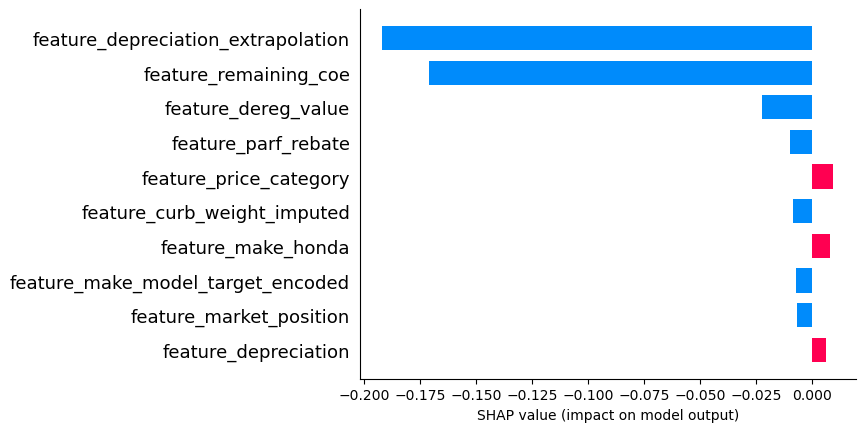

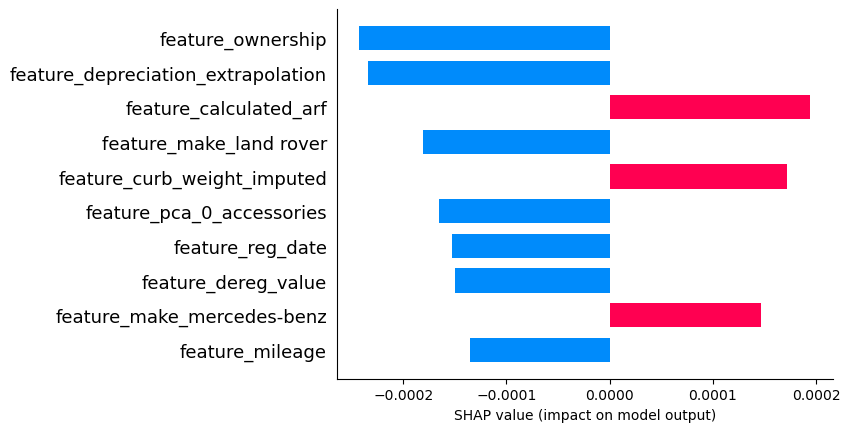

In [61]:
# Assuming you want to plot the SHAP values for the first sample and first output:
shap.bar_plot(shap_values[0,:,0], feature_names=test_df.columns, max_display=10)

# Or for the average SHAP values across all samples:
shap.bar_plot(np.mean(shap_values[:,:,0], axis=0), feature_names=test_df.columns, max_display=10)

# Training with a Smaller model

In [62]:
# Smaller model
class PricePredictionSmaller(nn.Module):
    def __init__(self, input_dim):
        super(PricePredictionSmaller, self).__init__()
        self.model = nn.Sequential(
            nn.Linear(input_dim, 64),
            nn.ReLU(),
            nn.Linear(64, 32),
            nn.ReLU(),
            nn.Linear(32, 1)
        )

    def forward(self, x):
        return self.model(x)

In [63]:
# Initialize the model, loss function, and optimizer
input_dim = X_train.shape[1]
patience = 10  # Number of epochs to wait for improvement

model = PricePredictionSmaller(input_dim)
criterion = nn.MSELoss()
optimizer = optim.Adam(model.parameters(), lr=1e-3, weight_decay=1e-5)

training_losses, validation_losses = train_model(model, train_loader, val_loader, criterion, optimizer, epochs=100)

Epoch 1/100, Train Loss: 0.1133, Val Loss: 0.0380
Epoch 2/100, Train Loss: 0.0360, Val Loss: 0.0312
Epoch 3/100, Train Loss: 0.0305, Val Loss: 0.0279
Epoch 4/100, Train Loss: 0.0255, Val Loss: 0.0338
Epoch 5/100, Train Loss: 0.0238, Val Loss: 0.0214
Epoch 6/100, Train Loss: 0.0225, Val Loss: 0.0285
Epoch 7/100, Train Loss: 0.0197, Val Loss: 0.0210
Epoch 8/100, Train Loss: 0.0184, Val Loss: 0.0211
Epoch 9/100, Train Loss: 0.0193, Val Loss: 0.0197
Epoch 10/100, Train Loss: 0.0161, Val Loss: 0.0230
Epoch 11/100, Train Loss: 0.0151, Val Loss: 0.0203
Epoch 12/100, Train Loss: 0.0147, Val Loss: 0.0203
Epoch 13/100, Train Loss: 0.0137, Val Loss: 0.0254
Epoch 14/100, Train Loss: 0.0131, Val Loss: 0.0215
Epoch 15/100, Train Loss: 0.0145, Val Loss: 0.0274
Epoch 16/100, Train Loss: 0.0110, Val Loss: 0.0232
Epoch 17/100, Train Loss: 0.0109, Val Loss: 0.0188
Epoch 18/100, Train Loss: 0.0097, Val Loss: 0.0201
Epoch 19/100, Train Loss: 0.0095, Val Loss: 0.0285
Epoch 20/100, Train Loss: 0.0104, Val Lo

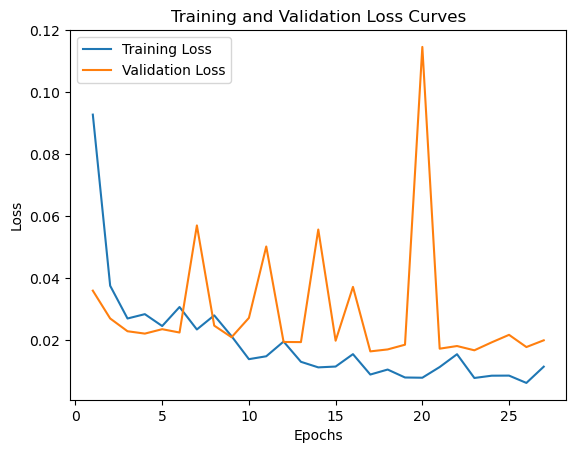

In [64]:
# Plot the loss curves
epochs = range(1, len(training_loss) + 1)
plt.plot(epochs, training_loss, label='Training Loss')
plt.plot(epochs, validation_loss, label='Validation Loss')

plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.title('Training and Validation Loss Curves')
plt.legend()
plt.show()

In [65]:
model.eval()

# Make predictions on the validation set
with torch.no_grad():
    val_predictions = model(X_val_tensor).numpy().flatten()
    val_targets = y_val_tensor.numpy().flatten()

# Calculate RMSE on the validation set (converting back from normalized to original scale)
val_predictions_original_scale = scaler_y.inverse_transform(val_predictions.reshape(-1, 1)).flatten()
val_targets_original_scale = scaler_y.inverse_transform(val_targets.reshape(-1, 1)).flatten()

# Calculate RMSE
rmse = np.sqrt(mean_squared_error(val_targets_original_scale, val_predictions_original_scale))
print(f"Validation RMSE: {rmse:.4f}")

Validation RMSE: 21962.7129


In [66]:
all_loss['PricePredictionSmaller'] = {
    'train_loss':training_loss,
    'val_loss':validation_loss
}
if rmse < best_rmse:
    best_model = model
    best_rmse = rmse

In [67]:
X_test_normalized = scaler_X.fit_transform(test_df.values)
X_test_tensor = torch.tensor(X_test_normalized, dtype=torch.float32)
test_dataset = TensorDataset(X_test_tensor)
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False)

predictions = []
model.eval()
with torch.no_grad():
    for inputs in test_loader:
        outputs = model(inputs[0])
        predictions.extend(outputs.numpy().flatten())

predictions = scaler_y.inverse_transform(np.array(predictions).reshape(-1, 1)).flatten()

test_results = pd.DataFrame({'Id': range(len(predictions)), 'Predicted': predictions})

test_results.to_csv('submission3.csv', index=False)

In [68]:
# KernelExplainer needs a function, so wrap the model to return predictions as numpy arrays
def model_predict(data):
    data = torch.from_numpy(data).float()  # Convert to tensor
    with torch.no_grad():
        return model(data).cpu().numpy()  # Get predictions as numpy

# Initialize KernelExplainer
explainer = shap.KernelExplainer(model_predict, X_test_normalized[:100])

# Calculate Shapley values (may take long)
shap_values = explainer.shap_values(X_test_normalized[:100])

  0%|          | 0/100 [00:00<?, ?it/s]

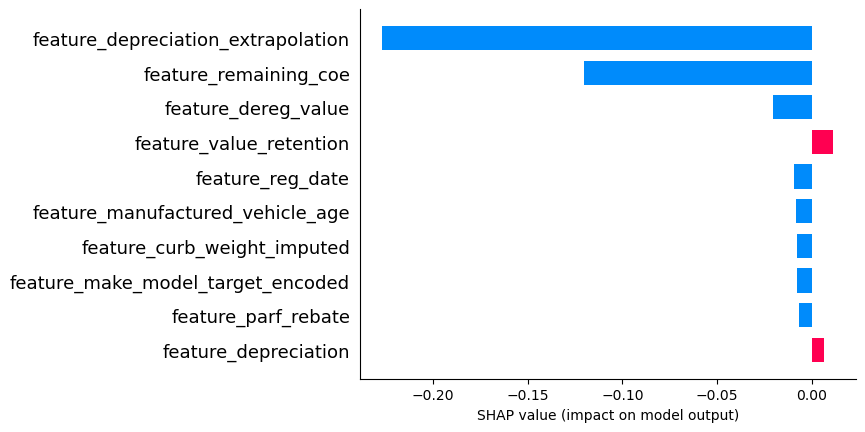

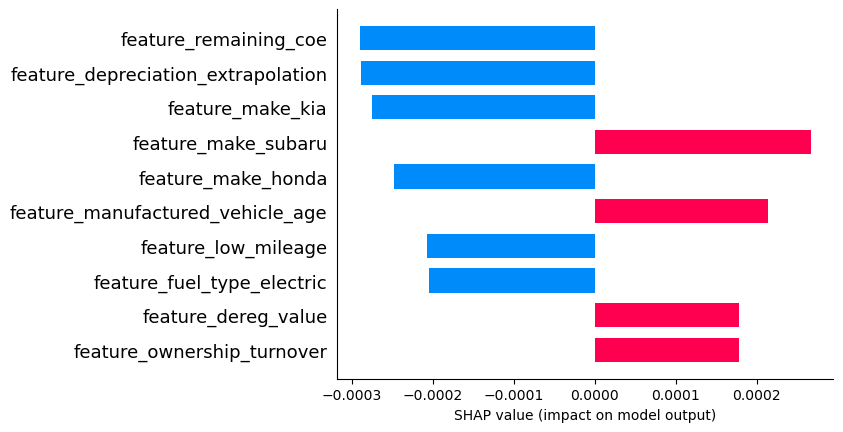

In [69]:
# Assuming you want to plot the SHAP values for the first sample and first output:
shap.bar_plot(shap_values[0,:,0], feature_names=test_df.columns, max_display=10)

# Or for the average SHAP values across all samples:
shap.bar_plot(np.mean(shap_values[:,:,0], axis=0), feature_names=test_df.columns, max_display=10)

# Using a different activation function (LeakyReLU)

In [70]:
# Different activation functions
class PricePredictionLeakyRelu(nn.Module):
    def __init__(self, input_dim):
        super(PricePredictionLeakyRelu, self).__init__()
        self.model = nn.Sequential(
            nn.Linear(input_dim, 128),
            nn.LeakyReLU(0.1),
            nn.Linear(128, 64),
            nn.LeakyReLU(0.1),
            nn.Linear(64, 32),
            nn.LeakyReLU(0.1),
            nn.Linear(32, 1)
        )

    def forward(self, x):
        return self.model(x)

In [71]:
# Initialize the model, loss function, and optimizer
input_dim = X_train.shape[1]
patience = 10  # Number of epochs to wait for improvement

model = PricePredictionLeakyRelu(input_dim)
criterion = nn.MSELoss()
optimizer = optim.Adam(model.parameters(), lr=1e-3, weight_decay=1e-5)

training_loss, validation_loss = train_model(model, train_loader, val_loader, criterion, optimizer, epochs=100)

Epoch 1/100, Train Loss: 0.1089, Val Loss: 0.0436
Epoch 2/100, Train Loss: 0.0363, Val Loss: 0.0283
Epoch 3/100, Train Loss: 0.0284, Val Loss: 0.0228
Epoch 4/100, Train Loss: 0.0222, Val Loss: 0.0324
Epoch 5/100, Train Loss: 0.0259, Val Loss: 0.0282
Epoch 6/100, Train Loss: 0.0222, Val Loss: 0.0360
Epoch 7/100, Train Loss: 0.0202, Val Loss: 0.0205
Epoch 8/100, Train Loss: 0.0192, Val Loss: 0.0201
Epoch 9/100, Train Loss: 0.0182, Val Loss: 0.0186
Epoch 10/100, Train Loss: 0.0195, Val Loss: 0.0187
Epoch 11/100, Train Loss: 0.0126, Val Loss: 0.0202
Epoch 12/100, Train Loss: 0.0152, Val Loss: 0.0207
Epoch 13/100, Train Loss: 0.0159, Val Loss: 0.0426
Epoch 14/100, Train Loss: 0.0117, Val Loss: 0.0173
Epoch 15/100, Train Loss: 0.0111, Val Loss: 0.0169
Epoch 16/100, Train Loss: 0.0094, Val Loss: 0.0229
Epoch 17/100, Train Loss: 0.0119, Val Loss: 0.0203
Epoch 18/100, Train Loss: 0.0105, Val Loss: 0.0167
Epoch 19/100, Train Loss: 0.0101, Val Loss: 0.0238
Epoch 20/100, Train Loss: 0.0091, Val Lo

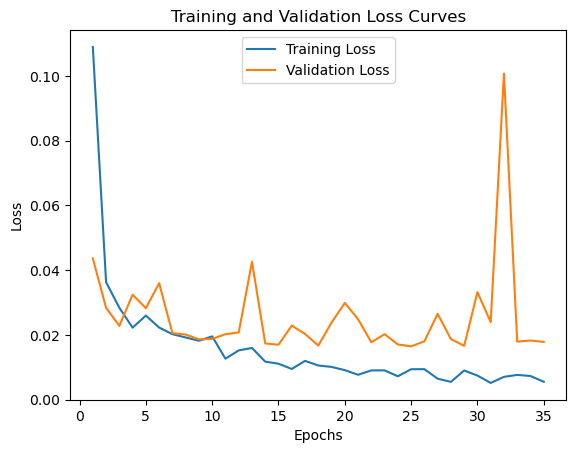

In [72]:
# Plot the loss curves
epochs = range(1, len(training_loss) + 1)
plt.plot(epochs, training_loss, label='Training Loss')
plt.plot(epochs, validation_loss, label='Validation Loss')

plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.title('Training and Validation Loss Curves')
plt.legend()
plt.show()

In [73]:
model.eval()

# Make predictions on the validation set
with torch.no_grad():
    val_predictions = model(X_val_tensor).numpy().flatten()
    val_targets = y_val_tensor.numpy().flatten()

# Calculate RMSE on the validation set (converting back from normalized to original scale)
val_predictions_original_scale = scaler_y.inverse_transform(val_predictions.reshape(-1, 1)).flatten()
val_targets_original_scale = scaler_y.inverse_transform(val_targets.reshape(-1, 1)).flatten()

# Calculate RMSE
rmse = np.sqrt(mean_squared_error(val_targets_original_scale, val_predictions_original_scale))
print(f"Validation RMSE: {rmse:.4f}")

Validation RMSE: 20766.4902


In [74]:
all_loss['PricePredictionLeakyRelu'] = {
    'train_loss':training_loss,
    'val_loss':validation_loss
}
if rmse < best_rmse:
    best_model = model
    best_rmse = rmse

In [75]:
X_test_normalized = scaler_X.fit_transform(test_df.values)
X_test_tensor = torch.tensor(X_test_normalized, dtype=torch.float32)
test_dataset = TensorDataset(X_test_tensor)
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False)

predictions = []
model.eval()
with torch.no_grad():
    for inputs in test_loader:
        outputs = model(inputs[0])
        predictions.extend(outputs.numpy().flatten())

predictions = scaler_y.inverse_transform(np.array(predictions).reshape(-1, 1)).flatten()

test_results = pd.DataFrame({'Id': range(len(predictions)), 'Predicted': predictions})

test_results.to_csv('submission4.csv', index=False)

In [76]:
# KernelExplainer needs a function, so wrap the model to return predictions as numpy arrays
def model_predict(data):
    data = torch.from_numpy(data).float()  # Convert to tensor
    with torch.no_grad():
        return model(data).cpu().numpy()  # Get predictions as numpy

# Initialize KernelExplainer
explainer = shap.KernelExplainer(model_predict, X_test_normalized[:100])

# Calculate Shapley values (may take long)
shap_values = explainer.shap_values(X_test_normalized[:100])

  0%|          | 0/100 [00:00<?, ?it/s]

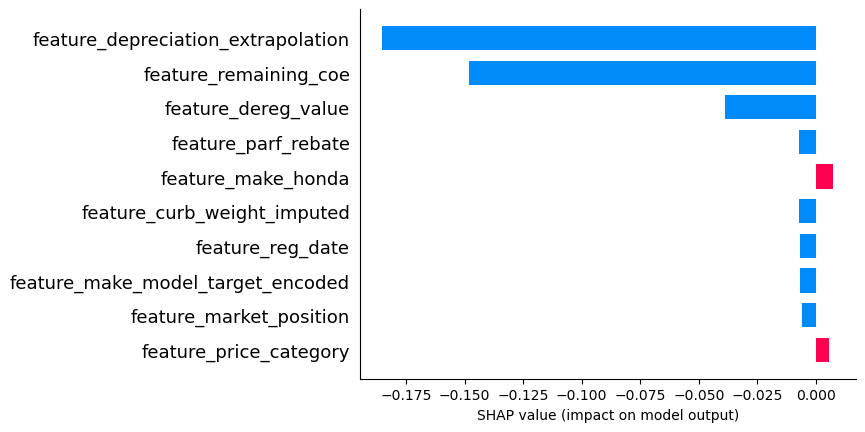

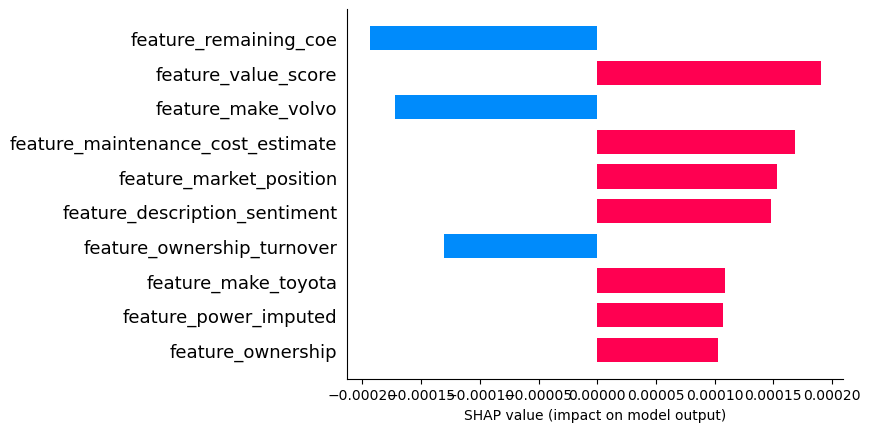

In [77]:
# Assuming you want to plot the SHAP values for the first sample and first output:
shap.bar_plot(shap_values[0,:,0], feature_names=test_df.columns, max_display=10)

# Or for the average SHAP values across all samples:
shap.bar_plot(np.mean(shap_values[:,:,0], axis=0), feature_names=test_df.columns, max_display=10)

# Adding Dropouts to the model

In [78]:
# Dropouts
class PricePredictionDropouts(nn.Module):
    def __init__(self, input_dim):
        super(PricePredictionDropouts, self).__init__()
        self.model = nn.Sequential(
            nn.Linear(input_dim, 256),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(256, 128),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(128, 64),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(64, 32),
            nn.ReLU(),
            nn.Linear(32, 1)
        )

    def forward(self, x):
        return self.model(x)

In [79]:
# Initialize the model, loss function, and optimizer
input_dim = X_train.shape[1]
patience = 10  # Number of epochs to wait for improvement

model = PricePredictionDropouts(input_dim)
criterion = nn.MSELoss()
optimizer = optim.Adam(model.parameters(), lr=1e-3, weight_decay=1e-5)

training_loss, validation_loss = train_model(model, train_loader, val_loader, criterion, optimizer, epochs=100)

Epoch 1/100, Train Loss: 0.1447, Val Loss: 0.0355
Epoch 2/100, Train Loss: 0.0907, Val Loss: 0.0409
Epoch 3/100, Train Loss: 0.0799, Val Loss: 0.0331
Epoch 4/100, Train Loss: 0.0664, Val Loss: 0.0318
Epoch 5/100, Train Loss: 0.0533, Val Loss: 0.0293
Epoch 6/100, Train Loss: 0.0550, Val Loss: 0.0334
Epoch 7/100, Train Loss: 0.0562, Val Loss: 0.0386
Epoch 8/100, Train Loss: 0.0651, Val Loss: 0.0566
Epoch 9/100, Train Loss: 0.0502, Val Loss: 0.0366
Epoch 10/100, Train Loss: 0.0455, Val Loss: 0.0371
Epoch 11/100, Train Loss: 0.0437, Val Loss: 0.0367
Epoch 12/100, Train Loss: 0.0458, Val Loss: 0.0327
Epoch 13/100, Train Loss: 0.0524, Val Loss: 0.0341
Epoch 14/100, Train Loss: 0.0335, Val Loss: 0.0216
Epoch 15/100, Train Loss: 0.0409, Val Loss: 0.0419
Epoch 16/100, Train Loss: 0.0517, Val Loss: 0.0271
Epoch 17/100, Train Loss: 0.0342, Val Loss: 0.0391
Epoch 18/100, Train Loss: 0.0353, Val Loss: 0.0721
Epoch 19/100, Train Loss: 0.0372, Val Loss: 0.0237
Epoch 20/100, Train Loss: 0.0393, Val Lo

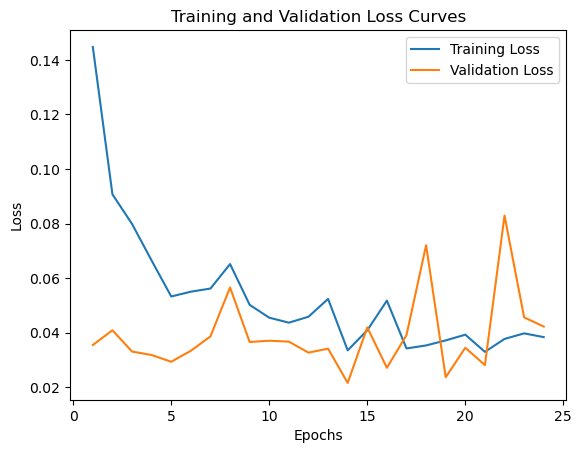

In [80]:
# Plot the loss curves
epochs = range(1, len(training_loss) + 1)
plt.plot(epochs, training_loss, label='Training Loss')
plt.plot(epochs, validation_loss, label='Validation Loss')

plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.title('Training and Validation Loss Curves')
plt.legend()
plt.show()

In [81]:
model.eval()

# Make predictions on the validation set
with torch.no_grad():
    val_predictions = model(X_val_tensor).numpy().flatten()
    val_targets = y_val_tensor.numpy().flatten()

# Calculate RMSE on the validation set (converting back from normalized to original scale)
val_predictions_original_scale = scaler_y.inverse_transform(val_predictions.reshape(-1, 1)).flatten()
val_targets_original_scale = scaler_y.inverse_transform(val_targets.reshape(-1, 1)).flatten()

# Calculate RMSE
rmse = np.sqrt(mean_squared_error(val_targets_original_scale, val_predictions_original_scale))
print(f"Validation RMSE: {rmse:.4f}")

Validation RMSE: 31977.9980


In [82]:
all_loss['PricePredictionDropouts'] = {
    'train_loss':training_loss,
    'val_loss':validation_loss
}
if rmse < best_rmse:
    best_model = model
    best_rmse = rmse

In [83]:
X_test_normalized = scaler_X.fit_transform(test_df.values)
X_test_tensor = torch.tensor(X_test_normalized, dtype=torch.float32)
test_dataset = TensorDataset(X_test_tensor)
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False)

predictions = []
model.eval()
with torch.no_grad():
    for inputs in test_loader:
        outputs = model(inputs[0])
        predictions.extend(outputs.numpy().flatten())

predictions = scaler_y.inverse_transform(np.array(predictions).reshape(-1, 1)).flatten()

test_results = pd.DataFrame({'Id': range(len(predictions)), 'Predicted': predictions})

test_results.to_csv('submission5.csv', index=False)

In [84]:
# KernelExplainer needs a function, so wrap the model to return predictions as numpy arrays
def model_predict(data):
    data = torch.from_numpy(data).float()  # Convert to tensor
    with torch.no_grad():
        return model(data).cpu().numpy()  # Get predictions as numpy

# Initialize KernelExplainer
explainer = shap.KernelExplainer(model_predict, X_test_normalized[:100])

# Calculate Shapley values (may take long)
shap_values = explainer.shap_values(X_test_normalized[:100])

  0%|          | 0/100 [00:00<?, ?it/s]

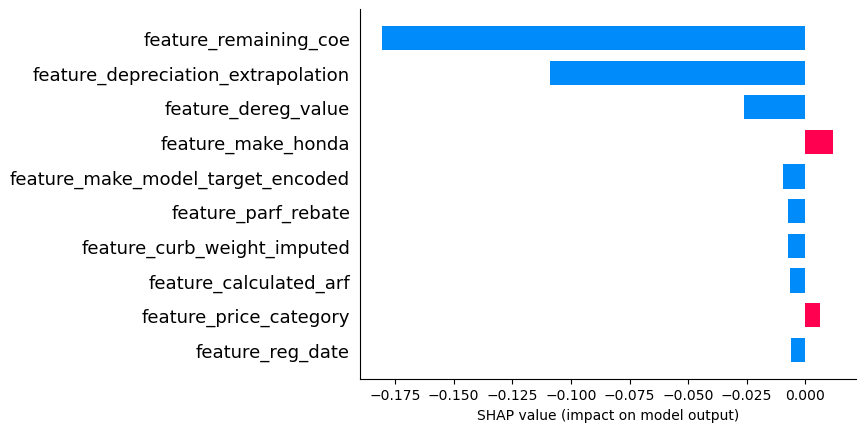

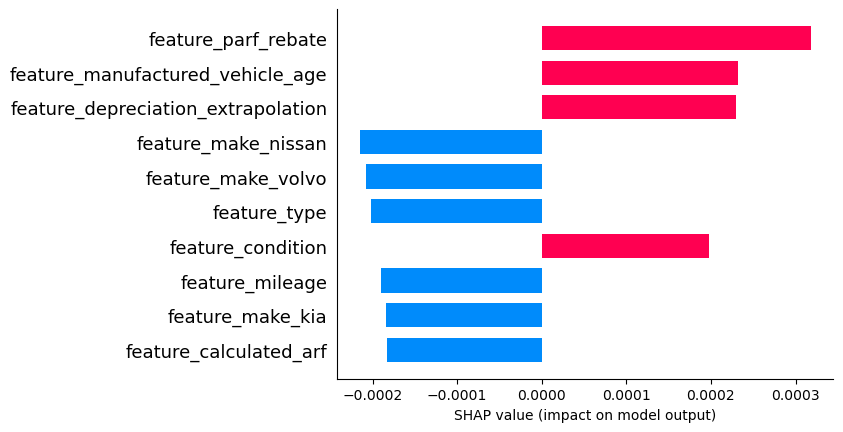

In [85]:
# Assuming you want to plot the SHAP values for the first sample and first output:
shap.bar_plot(shap_values[0,:,0], feature_names=test_df.columns, max_display=10)

# Or for the average SHAP values across all samples:
shap.bar_plot(np.mean(shap_values[:,:,0], axis=0), feature_names=test_df.columns, max_display=10)

# Batch Normalization

In [86]:
# Batch Normalization
class PricePredictionBatchNorm(nn.Module):
    def __init__(self, input_dim):
        super(PricePredictionBatchNorm, self).__init__()
        self.model = nn.Sequential(
            nn.Linear(input_dim, 128),
            nn.BatchNorm1d(128),
            nn.ReLU(),
            nn.Linear(128, 64),
            nn.BatchNorm1d(64),
            nn.ReLU(),
            nn.Linear(64, 32),
            nn.BatchNorm1d(32),
            nn.ReLU(),
            nn.Linear(32, 1)
        )

    def forward(self, x):
        return self.model(x)

In [87]:
# Initialize the model, loss function, and optimizer
input_dim = X_train.shape[1]
patience = 10  # Number of epochs to wait for improvement

model = PricePredictionBatchNorm(input_dim)
criterion = nn.MSELoss()
optimizer = optim.Adam(model.parameters(), lr=1e-3, weight_decay=1e-5)

training_loss, validation_loss = train_model(model, train_loader, val_loader, criterion, optimizer, epochs=100)

Epoch 1/100, Train Loss: 0.1921, Val Loss: 0.0354
Epoch 2/100, Train Loss: 0.0804, Val Loss: 0.0726
Epoch 3/100, Train Loss: 0.0627, Val Loss: 0.0540
Epoch 4/100, Train Loss: 0.0518, Val Loss: 0.0335
Epoch 5/100, Train Loss: 0.0477, Val Loss: 0.0344
Epoch 6/100, Train Loss: 0.0445, Val Loss: 0.0429
Epoch 7/100, Train Loss: 0.0434, Val Loss: 0.0399
Epoch 8/100, Train Loss: 0.0421, Val Loss: 0.0503
Epoch 9/100, Train Loss: 0.0347, Val Loss: 0.0485
Epoch 10/100, Train Loss: 0.0387, Val Loss: 0.0347
Epoch 11/100, Train Loss: 0.0283, Val Loss: 0.0372
Epoch 12/100, Train Loss: 0.0328, Val Loss: 0.0268
Epoch 13/100, Train Loss: 0.0282, Val Loss: 0.0649
Epoch 14/100, Train Loss: 0.0287, Val Loss: 0.0388
Epoch 15/100, Train Loss: 0.0279, Val Loss: 0.0313
Epoch 16/100, Train Loss: 0.0280, Val Loss: 0.0376
Epoch 17/100, Train Loss: 0.0257, Val Loss: 0.0433
Epoch 18/100, Train Loss: 0.0246, Val Loss: 0.0245
Epoch 19/100, Train Loss: 0.0242, Val Loss: 0.0392
Epoch 20/100, Train Loss: 0.0231, Val Lo

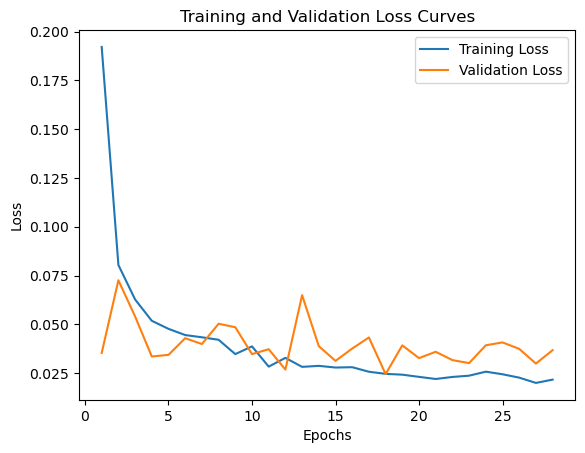

In [88]:
# Plot the loss curves
epochs = range(1, len(training_loss) + 1)
plt.plot(epochs, training_loss, label='Training Loss')
plt.plot(epochs, validation_loss, label='Validation Loss')

plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.title('Training and Validation Loss Curves')
plt.legend()
plt.show()

In [89]:
model.eval()

# Make predictions on the validation set
with torch.no_grad():
    val_predictions = model(X_val_tensor).numpy().flatten()
    val_targets = y_val_tensor.numpy().flatten()

# Calculate RMSE on the validation set (converting back from normalized to original scale)
val_predictions_original_scale = scaler_y.inverse_transform(val_predictions.reshape(-1, 1)).flatten()
val_targets_original_scale = scaler_y.inverse_transform(val_targets.reshape(-1, 1)).flatten()

# Calculate RMSE
rmse = np.sqrt(mean_squared_error(val_targets_original_scale, val_predictions_original_scale))
print(f"Validation RMSE: {rmse:.4f}")

Validation RMSE: 29824.2871


In [90]:
all_loss['PricePredictionBatchNorm'] = {
    'train_loss':training_loss,
    'val_loss':validation_loss
}
if rmse < best_rmse:
    best_model = model
    best_rmse = rmse

In [91]:
X_test_normalized = scaler_X.fit_transform(test_df.values)
X_test_tensor = torch.tensor(X_test_normalized, dtype=torch.float32)
test_dataset = TensorDataset(X_test_tensor)
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False)

predictions = []
model.eval()
with torch.no_grad():
    for inputs in test_loader:
        outputs = model(inputs[0])
        predictions.extend(outputs.numpy().flatten())

predictions = scaler_y.inverse_transform(np.array(predictions).reshape(-1, 1)).flatten()

test_results = pd.DataFrame({'Id': range(len(predictions)), 'Predicted': predictions})

test_results.to_csv('submission6.csv', index=False)

In [92]:
# KernelExplainer needs a function, so wrap the model to return predictions as numpy arrays
def model_predict(data):
    data = torch.from_numpy(data).float()  # Convert to tensor
    with torch.no_grad():
        return model(data).cpu().numpy()  # Get predictions as numpy

# Initialize KernelExplainer
explainer = shap.KernelExplainer(model_predict, X_test_normalized[:100])

# Calculate Shapley values (may take long)
shap_values = explainer.shap_values(X_test_normalized[:100])

  0%|          | 0/100 [00:00<?, ?it/s]

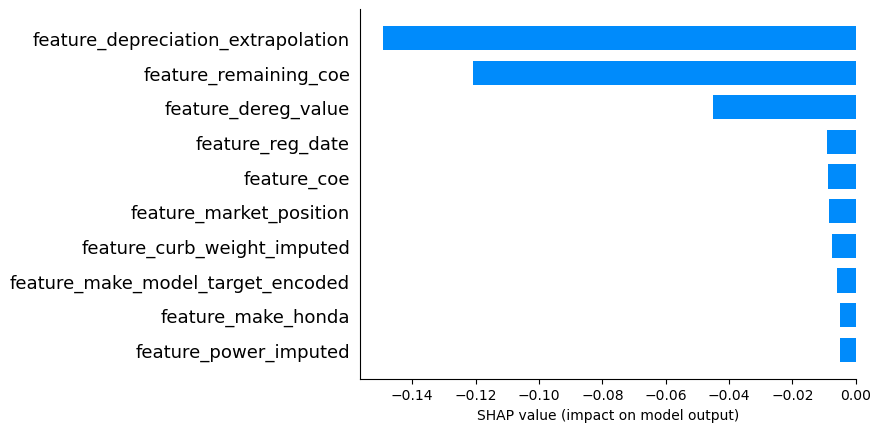

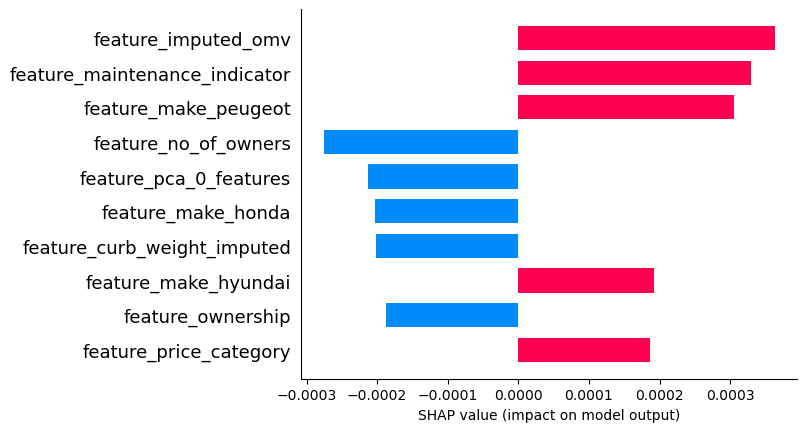

In [93]:
# Assuming you want to plot the SHAP values for the first sample and first output:
shap.bar_plot(shap_values[0,:,0], feature_names=test_df.columns, max_display=10)

# Or for the average SHAP values across all samples:
shap.bar_plot(np.mean(shap_values[:,:,0], axis=0), feature_names=test_df.columns, max_display=10)

# Residual Blocks

In [94]:
# Residual Connections
class ResidualBlock(nn.Module):
    def __init__(self, input_dim, output_dim):
        super(ResidualBlock, self).__init__()
        self.fc = nn.Linear(input_dim, output_dim)
        self.relu = nn.ReLU()

    def forward(self, x):
        out = self.fc(x)
        out = self.relu(out)
        return x + out  # Add residual connection

class PricePredictionResidual(nn.Module):
    def __init__(self, input_dim):
        super(PricePredictionResidual, self).__init__()
        self.input_fc = nn.Linear(input_dim, 128)
        self.residual1 = ResidualBlock(128, 128)
        self.residual2 = ResidualBlock(128, 128)
        self.output_fc = nn.Linear(128, 1)

    def forward(self, x):
        out = self.input_fc(x)
        out = self.residual1(out)
        out = self.residual2(out)
        out = self.output_fc(out)
        return out

In [95]:
# Initialize the model, loss function, and optimizer
input_dim = X_train.shape[1]
patience = 10  # Number of epochs to wait for improvement

model = PricePredictionResidual(input_dim)
criterion = nn.MSELoss()
optimizer = optim.Adam(model.parameters(), lr=1e-3, weight_decay=1e-5)

training_loss, validation_loss = train_model(model, train_loader, val_loader, criterion, optimizer, epochs=100)

Epoch 1/100, Train Loss: 0.0943, Val Loss: 0.1280
Epoch 2/100, Train Loss: 0.0532, Val Loss: 0.0371
Epoch 3/100, Train Loss: 0.0382, Val Loss: 0.0454
Epoch 4/100, Train Loss: 0.0246, Val Loss: 0.0270
Epoch 5/100, Train Loss: 0.0300, Val Loss: 0.0243
Epoch 6/100, Train Loss: 0.0202, Val Loss: 0.1079
Epoch 7/100, Train Loss: 0.0323, Val Loss: 0.0269
Epoch 8/100, Train Loss: 0.0169, Val Loss: 0.0269
Epoch 9/100, Train Loss: 0.0218, Val Loss: 0.0282
Epoch 10/100, Train Loss: 0.0185, Val Loss: 0.0213
Epoch 11/100, Train Loss: 0.0148, Val Loss: 0.0259
Epoch 12/100, Train Loss: 0.0143, Val Loss: 0.0191
Epoch 13/100, Train Loss: 0.0157, Val Loss: 0.0222
Epoch 14/100, Train Loss: 0.0200, Val Loss: 0.0226
Epoch 15/100, Train Loss: 0.0184, Val Loss: 0.0188
Epoch 16/100, Train Loss: 0.0145, Val Loss: 0.0205
Epoch 17/100, Train Loss: 0.0166, Val Loss: 0.0207
Epoch 18/100, Train Loss: 0.0111, Val Loss: 0.0231
Epoch 19/100, Train Loss: 0.0117, Val Loss: 0.0195
Epoch 20/100, Train Loss: 0.0192, Val Lo

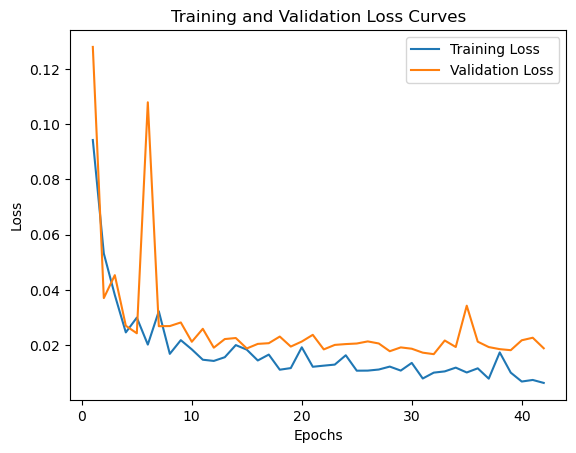

In [96]:
# Plot the loss curves
epochs = range(1, len(training_loss) + 1)
plt.plot(epochs, training_loss, label='Training Loss')
plt.plot(epochs, validation_loss, label='Validation Loss')

plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.title('Training and Validation Loss Curves')
plt.legend()
plt.show()

In [97]:
model.eval()

# Make predictions on the validation set
with torch.no_grad():
    val_predictions = model(X_val_tensor).numpy().flatten()
    val_targets = y_val_tensor.numpy().flatten()

# Calculate RMSE on the validation set (converting back from normalized to original scale)
val_predictions_original_scale = scaler_y.inverse_transform(val_predictions.reshape(-1, 1)).flatten()
val_targets_original_scale = scaler_y.inverse_transform(val_targets.reshape(-1, 1)).flatten()

# Calculate RMSE
rmse = np.sqrt(mean_squared_error(val_targets_original_scale, val_predictions_original_scale))
print(f"Validation RMSE: {rmse:.4f}")

Validation RMSE: 21382.7812


In [98]:
all_loss['PricePredictionResidual'] = {
    'train_loss':training_loss,
    'val_loss':validation_loss
}
if rmse < best_rmse:
    best_model = model
    best_rmse = rmse

In [99]:
X_test_normalized = scaler_X.fit_transform(test_df.values)
X_test_tensor = torch.tensor(X_test_normalized, dtype=torch.float32)
test_dataset = TensorDataset(X_test_tensor)
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False)

predictions = []
model.eval()
with torch.no_grad():
    for inputs in test_loader:
        outputs = model(inputs[0])
        predictions.extend(outputs.numpy().flatten())

predictions = scaler_y.inverse_transform(np.array(predictions).reshape(-1, 1)).flatten()

test_results = pd.DataFrame({'Id': range(len(predictions)), 'Predicted': predictions})

test_results.to_csv('submission7.csv', index=False)

In [100]:
# KernelExplainer needs a function, so wrap the model to return predictions as numpy arrays
def model_predict(data):
    data = torch.from_numpy(data).float()  # Convert to tensor
    with torch.no_grad():
        return model(data).cpu().numpy()  # Get predictions as numpy

# Initialize KernelExplainer
explainer = shap.KernelExplainer(model_predict, X_test_normalized[:100])

# Calculate Shapley values (may take long)
shap_values = explainer.shap_values(X_test_normalized[:100])

  0%|          | 0/100 [00:00<?, ?it/s]

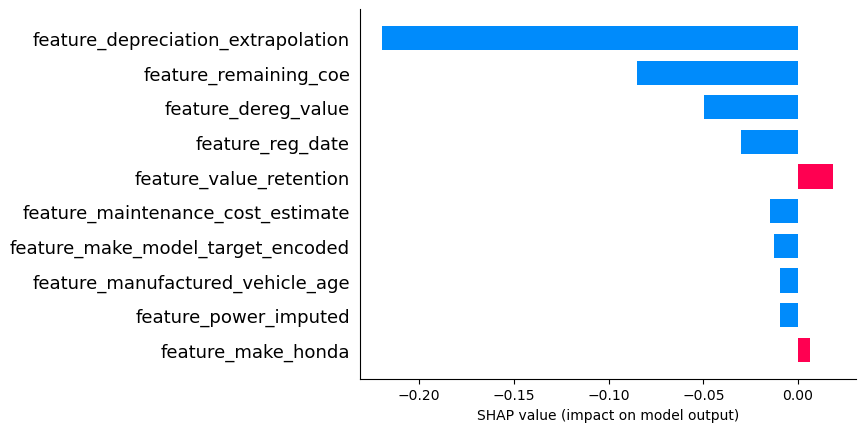

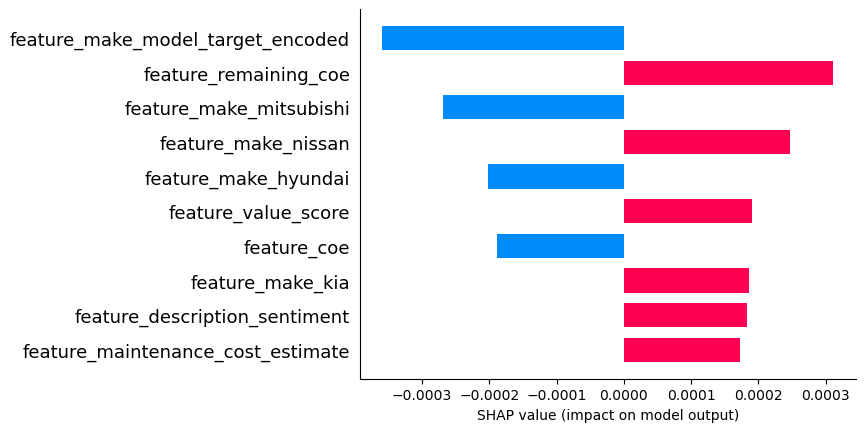

In [101]:
# Assuming you want to plot the SHAP values for the first sample and first output:
shap.bar_plot(shap_values[0,:,0], feature_names=test_df.columns, max_display=10)

# Or for the average SHAP values across all samples:
shap.bar_plot(np.mean(shap_values[:,:,0], axis=0), feature_names=test_df.columns, max_display=10)

# Gated Linear Units

In [102]:
# Gated Linear Units
class PricePredictionGLU(nn.Module):
    def __init__(self, input_dim):
        super(PricePredictionGLU, self).__init__()
        self.fc1 = nn.Linear(input_dim, 128)
        self.glu1 = nn.GLU()
        self.fc2 = nn.Linear(64, 64)  # Output of GLU is half the previous layer
        self.glu2 = nn.GLU()
        self.output = nn.Linear(32, 1)  # Single output for regression

    def forward(self, x):
        x = self.glu1(self.fc1(x))
        x = self.glu2(self.fc2(x))
        return self.output(x)

In [103]:
# Initialize the model, loss function, and optimizer
input_dim = X_train.shape[1]
patience = 10  # Number of epochs to wait for improvement

model = PricePredictionGLU(input_dim)
criterion = nn.MSELoss()
optimizer = optim.Adam(model.parameters(), lr=1e-3, weight_decay=1e-5)

best_val_loss = float('inf')
epochs_no_improve = 0

training_loss, validation_loss = train_model(model, train_loader, val_loader, criterion, optimizer, epochs=100)

Epoch 1/100, Train Loss: 0.0914, Val Loss: 0.0395
Epoch 2/100, Train Loss: 0.0353, Val Loss: 0.0298
Epoch 3/100, Train Loss: 0.0273, Val Loss: 0.0271
Epoch 4/100, Train Loss: 0.0238, Val Loss: 0.0255
Epoch 5/100, Train Loss: 0.0226, Val Loss: 0.0237
Epoch 6/100, Train Loss: 0.0172, Val Loss: 0.0268
Epoch 7/100, Train Loss: 0.0153, Val Loss: 0.0209
Epoch 8/100, Train Loss: 0.0153, Val Loss: 0.0195
Epoch 9/100, Train Loss: 0.0203, Val Loss: 0.0275
Epoch 10/100, Train Loss: 0.0127, Val Loss: 0.0207
Epoch 11/100, Train Loss: 0.0134, Val Loss: 0.0259
Epoch 12/100, Train Loss: 0.0108, Val Loss: 0.0208
Epoch 13/100, Train Loss: 0.0102, Val Loss: 0.0193
Epoch 14/100, Train Loss: 0.0123, Val Loss: 0.0197
Epoch 15/100, Train Loss: 0.0114, Val Loss: 0.0199
Epoch 16/100, Train Loss: 0.0101, Val Loss: 0.0216
Epoch 17/100, Train Loss: 0.0092, Val Loss: 0.0191
Epoch 18/100, Train Loss: 0.0087, Val Loss: 0.0186
Epoch 19/100, Train Loss: 0.0089, Val Loss: 0.0180
Epoch 20/100, Train Loss: 0.0077, Val Lo

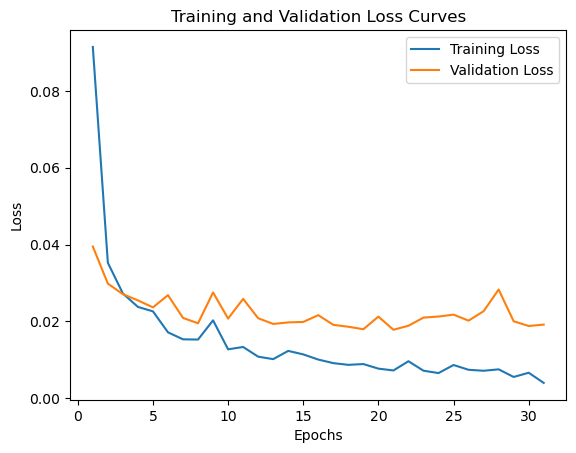

In [104]:
# Plot the loss curves
epochs = range(1, len(training_loss) + 1)
plt.plot(epochs, training_loss, label='Training Loss')
plt.plot(epochs, validation_loss, label='Validation Loss')

plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.title('Training and Validation Loss Curves')
plt.legend()
plt.show()

In [105]:
model.eval()

# Make predictions on the validation set
with torch.no_grad():
    val_predictions = model(X_val_tensor).numpy().flatten()
    val_targets = y_val_tensor.numpy().flatten()

# Calculate RMSE on the validation set (converting back from normalized to original scale)
val_predictions_original_scale = scaler_y.inverse_transform(val_predictions.reshape(-1, 1)).flatten()
val_targets_original_scale = scaler_y.inverse_transform(val_targets.reshape(-1, 1)).flatten()

# Calculate RMSE
rmse = np.sqrt(mean_squared_error(val_targets_original_scale, val_predictions_original_scale))
print(f"Validation RMSE: {rmse:.4f}")

Validation RMSE: 21542.7871


In [106]:
all_loss['PricePredictionGLU'] = {
    'train_loss':training_loss,
    'val_loss':validation_loss
}
if rmse < best_rmse:
    best_model = model
    best_rmse = rmse

In [107]:
X_test_normalized = scaler_X.fit_transform(test_df.values)
X_test_tensor = torch.tensor(X_test_normalized, dtype=torch.float32)
test_dataset = TensorDataset(X_test_tensor)
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False)

predictions = []
model.eval()
with torch.no_grad():
    for inputs in test_loader:
        outputs = model(inputs[0])
        predictions.extend(outputs.numpy().flatten())

predictions = scaler_y.inverse_transform(np.array(predictions).reshape(-1, 1)).flatten()

test_results = pd.DataFrame({'Id': range(len(predictions)), 'Predicted': predictions})

test_results.to_csv('submission8.csv', index=False)

In [108]:
# KernelExplainer needs a function, so wrap the model to return predictions as numpy arrays
def model_predict(data):
    data = torch.from_numpy(data).float()  # Convert to tensor
    with torch.no_grad():
        return model(data).cpu().numpy()  # Get predictions as numpy

# Initialize KernelExplainer
explainer = shap.KernelExplainer(model_predict, X_test_normalized[:100])

# Calculate Shapley values (may take long)
shap_values = explainer.shap_values(X_test_normalized[:100])

  0%|          | 0/100 [00:00<?, ?it/s]

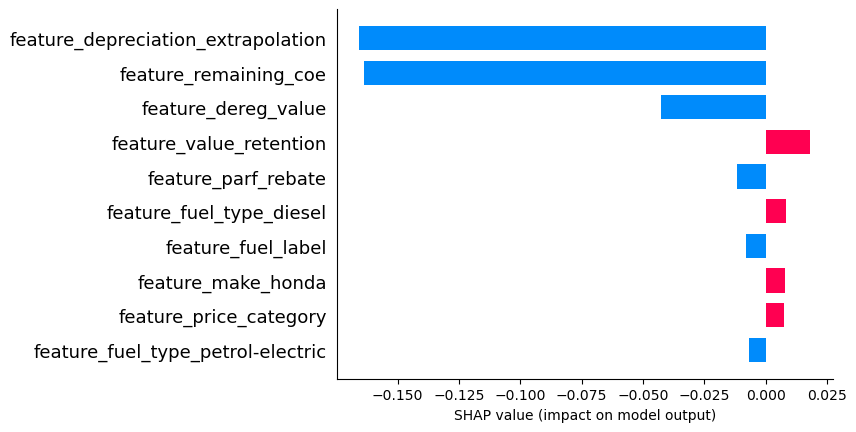

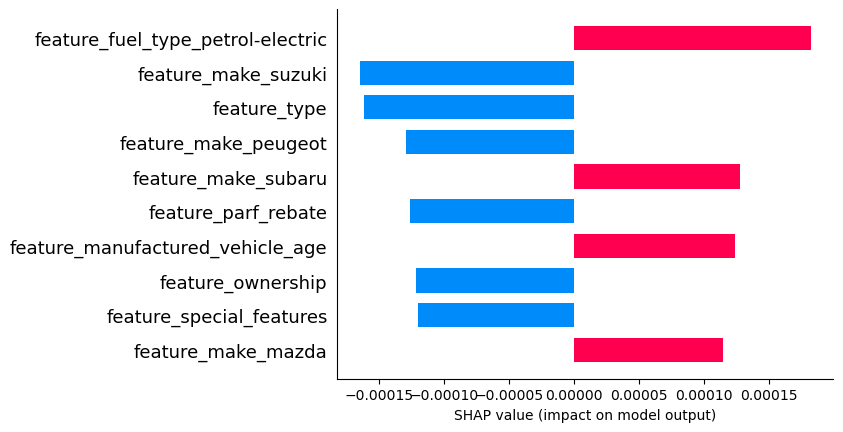

In [109]:
# Assuming you want to plot the SHAP values for the first sample and first output:
shap.bar_plot(shap_values[0,:,0], feature_names=test_df.columns, max_display=10)

# Or for the average SHAP values across all samples:
shap.bar_plot(np.mean(shap_values[:,:,0], axis=0), feature_names=test_df.columns, max_display=10)

# Plotting all loss curves

In [110]:
def plot_loss_curves(losses_dict):
    num_models = len(losses_dict)
    # Determine the number of rows and columns for a 2-row layout
    num_cols = math.ceil(num_models / 2)

    fig, axes = plt.subplots(2, num_cols, figsize=(5 * num_cols, 8), sharey=True)
    axes = axes.flatten()  # Flatten to easily index subplots for any number of models

    # Loop over each model and its losses
    for i, (model_name, losses) in enumerate(losses_dict.items()):
        epochs = range(1, len(losses['train_loss']) + 1)
        axes[i].plot(epochs, losses['train_loss'], label='Training Loss')
        axes[i].plot(epochs, losses['val_loss'], label='Validation Loss')
        axes[i].set_xlabel('Epochs')
        axes[i].set_ylabel('Loss')
        axes[i].set_title(f'{model_name} Loss Curves')
        axes[i].legend()

    # Hide any unused subplots (if number of models is odd)
    for j in range(i + 1, len(axes)):
        axes[j].axis('off')

    plt.tight_layout()
    plt.show()

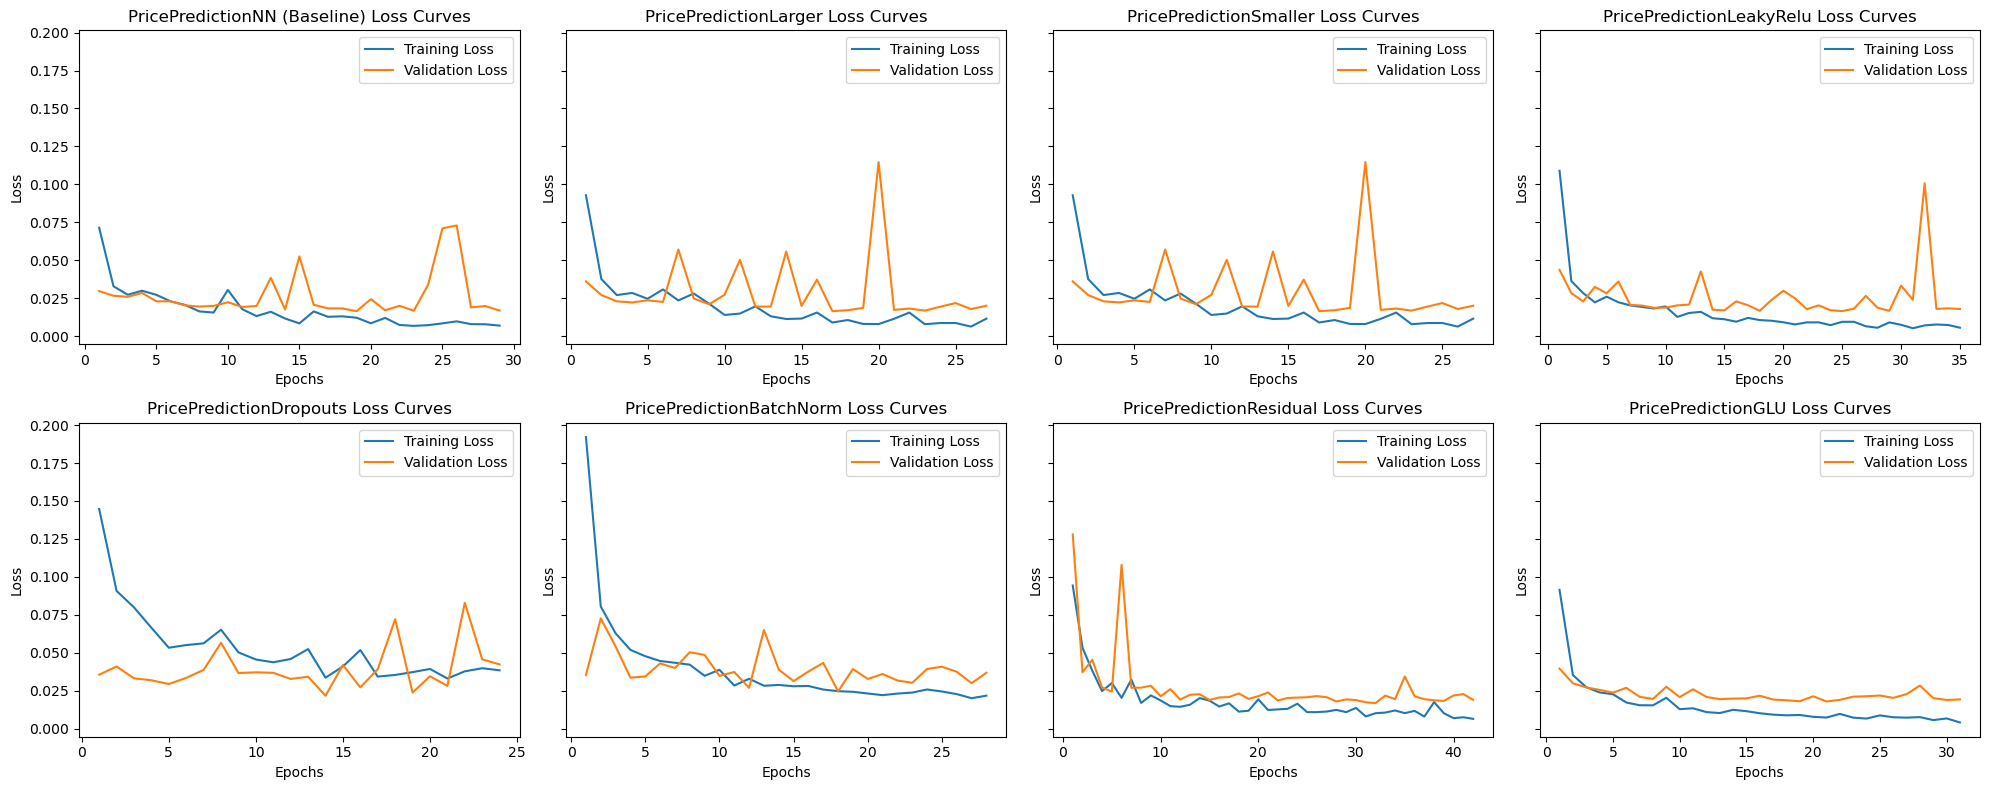

In [111]:
plot_loss_curves(all_loss)

# Best Model based on Validation RMSE

In [112]:
print(best_model)

PricePredictionNN(
  (model): Sequential(
    (0): Linear(in_features=63, out_features=128, bias=True)
    (1): ReLU()
    (2): Linear(in_features=128, out_features=64, bias=True)
    (3): ReLU()
    (4): Linear(in_features=64, out_features=32, bias=True)
    (5): ReLU()
    (6): Linear(in_features=32, out_features=1, bias=True)
  )
)
